In [1]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures,OneHotEncoder
from sklearn.metrics import mean_absolute_error
from scipy.special import expit,softmax # expit : 이진분류함수 , softmax : 다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier

In [2]:
# 데이터 연결
fish = pd.read_csv('data/fish_logistic.csv')

In [3]:
# 데이터 분리
data = fish[fish.columns[1:]].values
label = fish['Species'].values
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [4]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [ ]:
classes = train_label.unique()
classes = np.unique(train_label)

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [14]:
# lr = LogisticRegression()
# loss = 'log_loss' : LogisticRegression log함수
# max_iter = 10 : 10번 반복
# random_state=42 : 랜덤선택을 고정 - 연습할때 랜덤을 변경하면 정확도도 함께변경이 되어서 고정시킴 - 실제할때는 지워야함
# verbose=1 : 반복하면서 정보를 보여줌. / 설정하지 않으면 보여주지 않음.

sc = SGDClassifier(loss='log_loss',random_state=42)
train_score = []   # train 정확도 값 추가
test_score = []    # test 정확도 값 추가
#정답지 필요
classes = np.unique(train_label)

for i in range(300) :
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

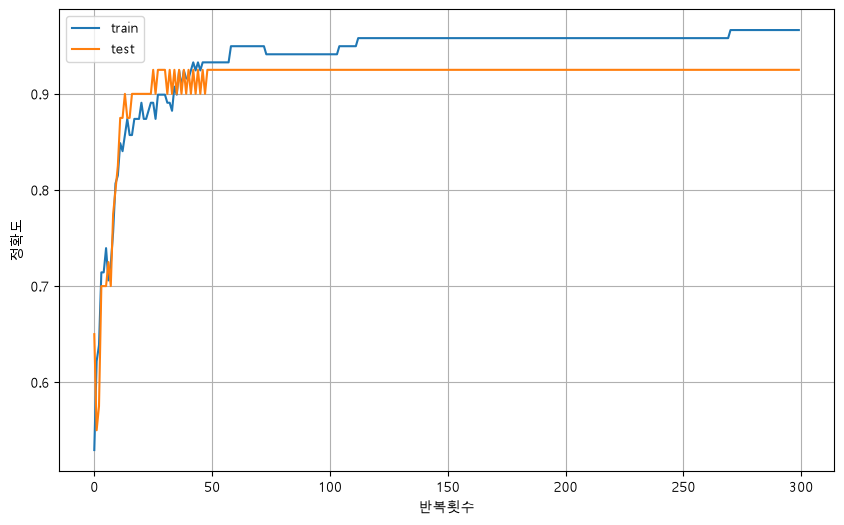

In [18]:
plt.figure(figsize=(10,6))
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('반복횟수')
plt.ylabel('정확도')
plt.grid()
plt.legend(['train','test'])
plt.show()

In [20]:
# tol : max_lter 가 반복할때 일정기간동안 변동이 없으면 자동으로 중지하는데 자동중지 해제
sc = SGDClassifier(loss = 'log_loss',max_iter=100,tol=None,random_state=42)
sc.fit(train_scaled,train_label)
print('train정확도 : ',sc.score(train_scaled,train_label))
print('test정확도 : ',sc.score(test_scaled,test_label))

train정확도 :  0.957983193277311
test정확도 :  0.925


In [ ]:
# sc.fit(train_scaled,train_label)
# print("train정확도 : ",sc.score(train_scaled,train_label))
# print("test정확도 : ",sc.score(test_scaled,test_label))